In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Pillar 2 — Public Investments & Cohesion/National Projects

This notebook analyses the public investment projects recorded in **OpenCoesione** (`2014–2020` programming cycle and national/regional cohesion funds: `FESR`, `FSE`, `FSC`, `POC`, `PAC`, `FEASR`) localized in **Cesena** (`040007`) and the 12 Emilia-Romagna peer municipalities.

**Design & Methodological Checks:**
1. **Multi-municipality allocation rule & single-municipality sensitivity:** OpenCoesione's `localizzazioni.zip` links each project (`COD_LOCALE_PROGETTO`) to one or more Italian municipalities. Following our platform convention (`core.sources.opencoesione`), multi-municipality projects have their allocated and disbursed euro amounts divided equally across the `n_comuni` distinct municipalities on the project. Because large regional or national infrastructure corridors span dozens of municipalities, we explicitly run a **sensitivity check restricting the sample to single-municipality projects (`n_comuni == 1`)** localized exclusively within each municipality.
2. **Execution rates & implementation lags:** We evaluate financial execution (`disbursement_rate_pct = disbursed / allocated * 100`), physical completion (`completion_rate_pct`, share of projects in `"concluso"` or `"liquidato"` status), implementation duration (`lag_days`, median days from start to effective completion), and schedule overrun (`delay_days`, effective minus planned completion date).
3. **Constant 2020 euro per capita:** Project values are deflated using the project's start year (or `2016` when missing) and normalized by 2020 resident population. Descriptive only.

In [2]:
from cifresignificative.studies.cesena.analysis.data import load_projects, load_demography
from cifresignificative.studies.cesena.analysis.investments import (
    summarize_investments_by_comune,
    summarize_investments_by_theme,
    annual_investment_flows,
)

projects = load_projects()
demo = load_demography()

print(f"Total OpenCoesione project-municipality rows across the 13 ER municipalities: {len(projects):,}")
print(f"Cesena (040007) projects: {int((projects['comune_id'] == '040007').sum()):,} "
      f"(single-municipality n_comuni==1: {int(((projects['comune_id'] == '040007') & (projects['n_comuni'] == 1)).sum()):,})")
print("Cesena projects by fund source:")
display(projects[projects["comune_id"] == "040007"].groupby("fund_source").agg(
    n_projects=("project_id", "count"),
    single_comune_n=("is_single_comune", "sum"),
    allocated_real_m_eur=("allocated_real_eur", lambda s: s.sum() / 1e6),
    disbursed_real_m_eur=("disbursed_real_eur", lambda s: s.sum() / 1e6),
).round(2))

Total OpenCoesione project-municipality rows across the 13 ER municipalities: 10,377
Cesena (040007) projects: 511 (single-municipality n_comuni==1: 385)
Cesena projects by fund source:


,n_projects,single_comune_n,allocated_real_m_eur,disbursed_real_m_eur
fund_source,,,,
FESR,149,145,14.14,14.11
FSC,57,49,14.04,13.89
FSE,294,181,25.11,24.51
PAC,11,10,0.60,0.29


## 1. Cross-Municipality Comparison: All Projects vs. Single-Municipality Projects (`n_comuni == 1`)
We compare Cesena against all 12 Emilia-Romagna peers first across all localized projects (equal-split rule for multi-municipality projects) and then strictly on single-municipality projects (`n_comuni == 1`).

In [3]:
sum_all = summarize_investments_by_comune(projects, demo, single_comune_only=False)
sum_single = summarize_investments_by_comune(projects, demo, single_comune_only=True)
show_cols = [
    "rank_allocated_pc", "comune", "core_peer", "n_projects", "single_comune_share_pct",
    "allocated_real_m_eur", "disbursed_real_m_eur", "allocated_real_pc", "disbursed_real_pc",
    "disbursement_rate_pct", "completion_rate_pct", "median_lag_days", "median_exec_days", "median_delay_days",
    "n_public_works", "public_works_share_pct", "public_works_disb_rate_pct", "comune_actor_share_pct",
]
print("All localized OpenCoesione projects (equal split across n_comuni), ranked by real allocated EUR per capita:")
display(sum_all[[c for c in show_cols if c in sum_all.columns]].round(2))

print("\nSensitivity check — Single-municipality projects ONLY (n_comuni == 1), ranked by real allocated EUR per capita:")
display(sum_single[[c for c in show_cols if c in sum_single.columns]].round(2))

for label, tbl in [("All projects (equal split)", sum_all), ("Single-comune only (n_comuni == 1)", sum_single)]:
    ces = tbl[tbl["comune_id"] == "040007"].iloc[0]
    peers_core = tbl[(tbl["comune_id"] != "040007") & (tbl["core_peer"])]
    peers_all = tbl[tbl["comune_id"] != "040007"]
    print(f"{label} -> Cesena alloc_pc={ces['allocated_real_pc']:.1f} EUR (Core med={peers_core['allocated_real_pc'].median():.1f}, ER med={peers_all['allocated_real_pc'].median():.1f}, rank={int(ces['rank_allocated_pc'])}/13) | "
          f"disb_rate={ces['disbursement_rate_pct']:.1f}% (Core med={peers_core['disbursement_rate_pct'].median():.1f}%) | "
          f"completion={ces['completion_rate_pct']:.1f}% (Core med={peers_core['completion_rate_pct'].median():.1f}%) | "
          f"median_lag={ces['median_lag_days']:.0f}d (Core med={peers_core['median_lag_days'].median():.0f}d)")

All localized OpenCoesione projects (equal split across n_comuni), ranked by real allocated EUR per capita:


,rank_allocated_pc,comune,core_peer,n_projects,single_comune_share_pct,allocated_real_m_eur,disbursed_real_m_eur,allocated_real_pc,disbursed_real_pc,disbursement_rate_pct,completion_rate_pct,median_lag_days,median_exec_days,median_delay_days,n_public_works,public_works_share_pct,public_works_disb_rate_pct,comune_actor_share_pct
0,1,Bologna,False,2628,90.07,929.82,816.91,2351.49,2065.96,87.86,94.60,398.0,357.0,0.0,146,5.56,58.55,4.83
1,2,Ravenna,True,665,73.23,205.09,167.33,1296.01,1057.38,81.59,96.84,471.0,416.5,-1.0,50,7.52,64.42,4.36
2,3,Reggio nell'Emilia,True,959,80.71,200.19,184.94,1170.14,1080.98,92.38,92.28,415.0,365.0,-3.0,66,6.88,86.99,6.36
3,4,Modena,False,1120,82.05,183.70,174.85,971.89,925.06,95.18,93.93,414.0,370.0,0.0,72,6.43,91.57,3.57
4,5,Ferrara,False,733,78.85,120.44,108.71,906.22,818.02,90.27,92.91,416.5,365.0,-1.0,69,9.41,81.47,6.28
5,6,Piacenza,False,652,80.37,88.89,82.63,852.61,792.49,92.95,95.09,409.5,375.0,-3.0,27,4.14,77.25,3.37
6,7,Parma,False,1013,83.22,165.71,149.33,826.65,744.94,90.12,93.88,400.0,364.0,-1.0,50,4.94,75.05,2.37
7,8,Rimini,True,748,79.28,122.40,109.29,819.62,731.86,89.29,95.86,433.5,395.0,-2.0,44,5.88,80.46,4.95
8,9,Imola,True,283,75.27,50.03,44.35,708.72,628.35,88.66,92.23,398.0,333.0,-3.0,18,6.36,77.88,3.53
9,10,Cesena,False,511,75.34,53.90,52.80,553.01,541.69,97.95,95.11,414.0,382.0,-1.0,23,4.50,98.61,3.72



Sensitivity check — Single-municipality projects ONLY (n_comuni == 1), ranked by real allocated EUR per capita:


,rank_allocated_pc,comune,core_peer,n_projects,single_comune_share_pct,allocated_real_m_eur,disbursed_real_m_eur,allocated_real_pc,disbursed_real_pc,disbursement_rate_pct,completion_rate_pct,median_lag_days,median_exec_days,median_delay_days,n_public_works,public_works_share_pct,public_works_disb_rate_pct,comune_actor_share_pct
0,1,Bologna,False,2367,100.0,882.88,771.52,2232.79,1951.15,87.39,95.01,379.0,334.0,0.0,141,5.96,57.98,5.37
1,2,Ravenna,True,487,100.0,195.71,158.11,1236.76,999.12,80.79,96.51,443.0,381.0,0.0,46,9.45,64.39,5.95
2,3,Reggio nell'Emilia,True,774,100.0,185.40,170.94,1083.66,999.16,92.20,91.21,397.5,336.0,-4.0,59,7.62,86.91,7.88
3,4,Modena,False,919,100.0,170.34,163.43,901.23,864.64,95.94,93.80,386.0,364.0,0.0,66,7.18,94.91,4.24
4,5,Ferrara,False,578,100.0,110.37,99.95,830.47,752.08,90.56,91.70,391.0,360.0,-1.0,64,11.07,83.27,7.96
5,6,Piacenza,False,524,100.0,82.75,76.62,793.64,734.91,92.60,94.66,388.0,345.0,-4.0,24,4.58,77.42,4.20
6,7,Rimini,True,593,100.0,114.59,101.60,767.32,680.34,88.67,95.45,407.0,351.5,-2.0,41,6.91,80.54,6.24
7,8,Parma,False,843,100.0,153.44,139.55,765.44,696.18,90.95,93.83,385.0,345.0,-1.0,42,4.98,77.44,2.49
8,9,Imola,True,213,100.0,45.49,39.93,644.46,565.75,87.79,90.61,364.0,276.0,-3.0,15,7.04,78.04,4.69
9,10,Cesena,False,385,100.0,47.28,46.32,485.08,475.29,97.98,94.81,380.0,315.0,-1.0,19,4.94,99.80,4.94


All projects (equal split) -> Cesena alloc_pc=553.0 EUR (Core med=764.2, ER med=839.6, rank=10/13) | disb_rate=98.0% (Core med=89.0%) | completion=95.1% (Core med=92.5%) | median_lag=414d (Core med=414d)
Single-comune only (n_comuni == 1) -> Cesena alloc_pc=485.1 EUR (Core med=705.9, ER med=780.5, rank=10/13) | disb_rate=98.0% (Core med=88.2%) | completion=94.8% (Core med=92.4%) | median_lag=380d (Core med=393d)


## 2. Thematic Breakdown (`OC_TEMA_SINTETICO`): Where Do Cesena's Projects Concentrate?
We compare Cesena's project portfolio against the Core Peer median across OpenCoesione's synthetic policy themes.

Cesena vs Core Peer median by OpenCoesione synthetic policy theme:


,tema,cesena_n_projects,cesena_alloc_real_m_eur,cesena_disb_real_m_eur,cesena_share_alloc_pct,cesena_alloc_real_pc,peer_alloc_real_pc,cesena_disbursement_rate_pct,peer_disbursement_rate_pct,cesena_completion_rate_pct,peer_completion_rate_pct,cesena_median_lag_days,peer_median_lag_days
0,Occupazione e lavoro,180,14.93,14.93,27.71,153.22,143.59,100.00,100.00,100.00,100.00,637.5,582.75
1,Istruzione e formazione,106,9.11,8.23,16.91,93.49,94.40,90.34,84.76,84.91,82.62,304.5,254.00
2,Ricerca e innovazione,18,9.06,9.04,16.80,92.92,33.93,99.79,97.01,88.89,85.42,910.0,1067.50
3,Inclusione sociale e salute,47,6.21,6.17,11.52,63.71,93.23,99.31,95.23,93.62,95.34,648.5,618.75
4,Cultura e turismo,4,6.20,6.20,11.50,63.59,71.48,100.00,99.16,100.00,100.00,2277.0,1532.75
5,Reti e servizi digitali,107,4.84,4.72,8.98,49.67,36.11,97.58,96.06,98.13,97.31,295.0,305.75
6,Competitività delle imprese,43,1.98,1.95,3.67,20.28,26.95,98.76,95.79,97.67,98.15,536.0,558.50
7,Trasporti e mobilità,2,1.01,1.01,1.87,10.33,111.69,100.00,96.62,100.00,75.00,2019.5,1581.00
8,Ambiente,1,0.36,0.34,0.66,3.65,37.75,94.29,20.60,0.00,50.00,1162.0,1574.50
9,Energia,2,0.18,0.18,0.33,1.82,1.81,100.00,100.00,100.00,100.00,502.0,987.00


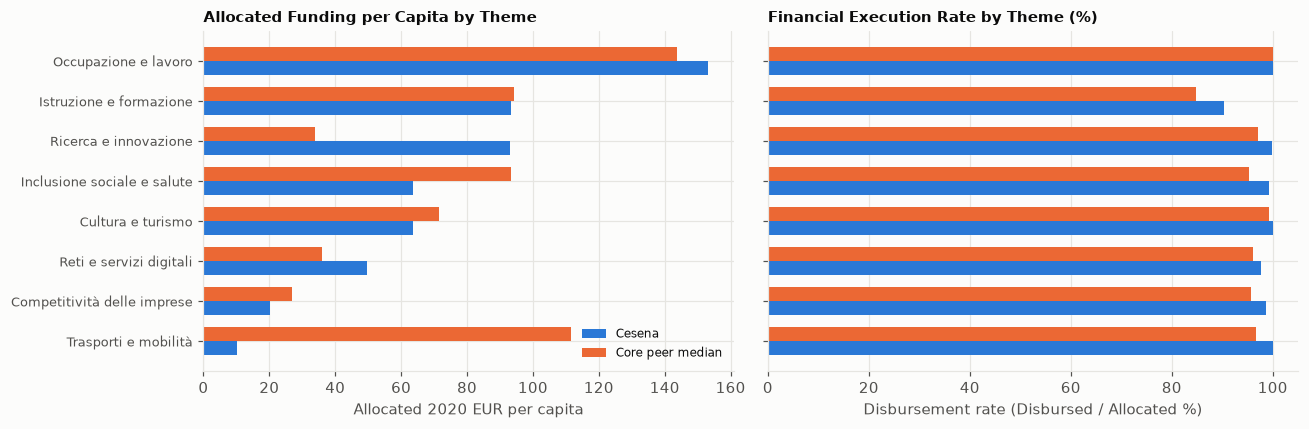

In [4]:
theme_tbl = summarize_investments_by_theme(projects, demo, core_only=True)
print("Cesena vs Core Peer median by OpenCoesione synthetic policy theme:")
display(theme_tbl.round(2))

top_t = theme_tbl.head(8).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
y = np.arange(len(top_t))
axes[0].barh(y - 0.18, top_t["cesena_alloc_real_pc"], height=0.35, color=ITALY_C, label="Cesena")
axes[0].barh(y + 0.18, top_t["peer_alloc_real_pc"], height=0.35, color=EU_C, label="Core peer median")
axes[0].set_yticks(y, [t[:34] for t in top_t["tema"]], fontsize=8.5)
axes[0].set_xlabel("Allocated 2020 EUR per capita")
axes[0].set_title("Allocated Funding per Capita by Theme", fontsize=9.5)
axes[0].legend(fontsize=8)

axes[1].barh(y - 0.18, top_t["cesena_disbursement_rate_pct"], height=0.35, color=ITALY_C, label="Cesena")
axes[1].barh(y + 0.18, top_t["peer_disbursement_rate_pct"], height=0.35, color=EU_C, label="Core peer median")
axes[1].set_yticks(y, ["" for _ in top_t["tema"]])
axes[1].set_xlabel("Disbursement rate (Disbursed / Allocated %)")
axes[1].set_title("Financial Execution Rate by Theme (%)", fontsize=9.5)
plt.tight_layout()
plt.show()

## 3. Annual Investment Flows & Largest Individual Projects in Cesena
We inspect the annual profile of project starts (`start_year`) and list the top 15 public investment projects localized in Cesena.

In [5]:
flows = annual_investment_flows(projects, demo)
ces_flows = flows[flows["comune_id"] == "040007"]
print("Cesena annual OpenCoesione project starts and real per-capita allocations/disbursements by start_year:")
display(ces_flows.round(2))

ces_top = (
    projects[projects["comune_id"] == "040007"]
    .sort_values("allocated_real_eur", ascending=False)
    [[
        "project_id", "fund_source", "theme_code", "n_comuni", "start_year",
        "allocated_real_eur", "disbursed_real_eur", "status", "lag_days", "title",
    ]]
    .head(15)
    .copy()
)
ces_top["allocated_real_m_eur"] = ces_top["allocated_real_eur"] / 1e6
ces_top["disbursed_real_m_eur"] = ces_top["disbursed_real_eur"] / 1e6
print("Top 15 OpenCoesione projects localized in Cesena by equal-split real allocated funding:")
display(ces_top[["project_id", "fund_source", "theme_code", "n_comuni", "start_year", "allocated_real_m_eur", "disbursed_real_m_eur", "status", "lag_days", "title"]].round(3))

Cesena annual OpenCoesione project starts and real per-capita allocations/disbursements by start_year:


,comune_id,year,projects_started_n,projects_allocated_real_eur,projects_disbursed_real_eur,projects_allocated_real_pc,projects_disbursed_real_pc
123,040007,2012,1,1139375.24,1139375.24,11.79,11.79
124,040007,2014,8,447903.77,351530.86,4.62,3.62
125,040007,2015,47,5716702.39,5601216.91,59.13,57.93
126,040007,2016,54,13999909.69,13913036.51,145.10,144.20
127,040007,2017,78,7609393.21,7376235.92,78.98,76.56
128,040007,2018,76,5881275.11,5831947.94,60.80,60.29
129,040007,2019,73,8147250.43,8145260.64,83.63,83.61
130,040007,2020,69,5313822.58,5277352.49,54.52,54.15
131,040007,2021,61,3579492.01,3578715.60,37.09,37.08
132,040007,2022,19,945699.50,945699.50,9.83,9.83


Top 15 OpenCoesione projects localized in Cesena by equal-split real allocated funding:


,project_id,fund_source,theme_code,n_comuni,start_year,allocated_real_m_eur,disbursed_real_m_eur,status,lag_days,title
9422,23EMPG/2016/312775,FSC,istruzione_cultura,1,2016,2.688,2.688,concluso,2880.0,La Malatestiana Progetto di completamento e r...
9125,5MTRA1E5029,FSC,istruzione_cultura,1,2016,1.545,1.545,concluso,2570.0,"Riqualificazione di piazza Bufalini, piazza Al..."
249,23EMPG/2016/193938,FESR,istruzione_cultura,1,2015,1.466,1.466,concluso,1981.0,Casa Bufalini
1939,23EMPG/2015/737587,FESR,ricerca_innovazione,1,2016,1.426,1.426,concluso,1120.0,Ricerca industriale ed innovazione nel compart...
9634,23EMPG/2017/533914,FSC,ricerca_innovazione,1,2017,1.220,1.220,concluso,2347.0,Casa Bufalini: un Laboratorio Aperto per Cesena
1829,23EMPG/2018/629448,FESR,ricerca_innovazione,1,2019,1.176,1.176,concluso,1088.0,Smart Specialized Sustainable Orchard (S3O)
2286,23EMPG/2015/737566,FESR,ricerca_innovazione,1,2016,1.142,1.142,concluso,1083.0,Collezioni microbiche regionali: la biodiversi...
10000,1MISEERAU06,FSC,inclusione_rigenerazione,1,2012,1.139,1.139,concluso,2643.0,FORO ANNONARIO. PALAZZO COMUNALE: INTERVENTO D...
247,23EMPG/2015/737593,FESR,ricerca_innovazione,1,2016,1.134,1.134,concluso,1030.0,FOOD CROSSING DISTRICT Simbiosi industriale: d...
9080,23EMPG/2018/632088,FSC,ricerca_innovazione,1,2019,1.121,1.121,concluso,1020.0,Servizi Big Data In e Out per Industria 4.0: d...


## 5. OpenCoesione 2021–2027 Programming Cycle: Early Allocation & Execution
We inspect the ongoing **2021–2027 European and national cohesion programming cycle** (`progetti_esteso_EMR_2021-2027.zip`) across the 13 Emilia-Romagna peer municipalities to evaluate whether Cesena improved its per-capita cohesion funding allocation compared to the `2014–2020` cycle (where it ranked 10th of 13).

In [6]:
from cifresignificative.studies.cesena.analysis.data import load_projects_2127
from cifresignificative.studies.cesena.analysis.investments import summarize_opencoesione_2127_benchmarks

proj_2127 = load_projects_2127()
print(f"Total 2021-2027 OpenCoesione project-municipality rows in ER benchmark cities: {len(proj_2127):,}")
print(f"Cesena 2021-2027 projects: {int((proj_2127['comune_id'] == '040007').sum()):,}")

bench_2127_core = summarize_opencoesione_2127_benchmarks(proj_2127, demo, core_only=True)
bench_2127_all = summarize_opencoesione_2127_benchmarks(proj_2127, demo, core_only=False)

print("\nOpenCoesione 2021-2027 Benchmark — Cesena vs Core Peers:")
display(bench_2127_core[["label", "formatted_cesena", "formatted_peer", "gap_pct"]].rename(columns={"formatted_cesena": "Cesena", "formatted_peer": "Core Peer Median", "gap_pct": "Gap vs Peer (%)"}).round(1))

ces_21 = proj_2127[proj_2127["comune_id"] == "040007"]
print("\nCesena 2021-2027 projects by theme:")
display(ces_21.groupby("theme_label").agg(
    n_projects=("project_id", "count"),
    allocated_m_eur=("allocated_real_eur", lambda s: s.sum() / 1e6),
    disbursed_m_eur=("disbursed_real_eur", lambda s: s.sum() / 1e6),
).sort_values("allocated_m_eur", ascending=False).round(2))

Total 2021-2027 OpenCoesione project-municipality rows in ER benchmark cities: 4,567
Cesena 2021-2027 projects: 229



OpenCoesione 2021-2027 Benchmark — Cesena vs Core Peers:


,label,Cesena,Core Peer Median,Gap vs Peer (%)
0,Number of 2021-2027 Cohesion Projects,229,300,-23.8
1,Total 2021-2027 Public Allocation (nominal EUR),"89,367,554","69,254,819",29.0
2,Allocated Cohesion Funds per Capita (nominal E...,930.3,503.7,84.7
3,Disbursed Cohesion Funds per Capita (nominal E...,319.2,106.7,199.2
4,Financial Disbursement Rate (%),34.3%,21.3%,61.0
5,Physical Completion/Liquidation Rate (%),40.6%,37.8%,7.5



Cesena 2021-2027 projects by theme:


,n_projects,allocated_m_eur,disbursed_m_eur
theme_label,,,
Ambiente,1,0.0,0.0
Competitività delle imprese,107,0.0,0.0
Cultura e turismo,1,0.0,0.0
Energia,8,0.0,0.0
Inclusione sociale e salute,13,0.0,0.0
Istruzione e formazione,79,0.0,0.0
Occupazione e lavoro,2,0.0,0.0
Reti e servizi digitali,3,0.0,0.0
Ricerca e innovazione,14,0.0,0.0


## Takeaways (Pillar 2 — Public Investments, 13 ER Municipalities; Descriptive)

- **2014–2020 (`robust` as a description).** Allocations per resident are below most peers, and the disbursement rate is the highest of the 13. Public works rest on few, small projects, so the rate is not by itself a measure of administrative capacity.
- **2021–2027 (`sensitive`).** High allocations so far in an open cycle, in nominal euro; three projects make up about half.
- **PNRR procurement (`retracted`).** The file names no contracting authority or location, so tenders cannot be attributed to municipalities.
- **Limits.** All statements are descriptive associations for one municipality, never causal claims. The figures are in the table below and in `reports/findings.md`, both computed by `analysis/claims.py`.

In [7]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

print("Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(claims_for_notebook("02"))

Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):


,id,text,window,source
0,oc1420_alloc_pc,€553,2014-2020 cycle,projects.parquet
1,oc1420_alloc_pc_rank,#10 of 13,2014-2020 cycle,projects.parquet
2,oc1420_alloc_pc_core,€764,2014-2020 cycle,projects.parquet
3,oc1420_disb_rate,98.0%,2014-2020 cycle,projects.parquet
4,oc1420_disb_rate_rank,#1 of 13,2014-2020 cycle,projects.parquet
5,oc1420_disb_rate_core,89.0%,2014-2020 cycle,projects.parquet
6,oc1420_pw_n,23,2014-2020 cycle,projects.parquet
7,oc1420_pw_rate,98.6%,2014-2020 cycle,projects.parquet
8,oc1420_pw_rate_rank,#1 of 13,2014-2020 cycle,projects.parquet
9,oc1420_pw_alloc_pc,€111,2014-2020 cycle,projects.parquet
